https://astra.datastax.com/
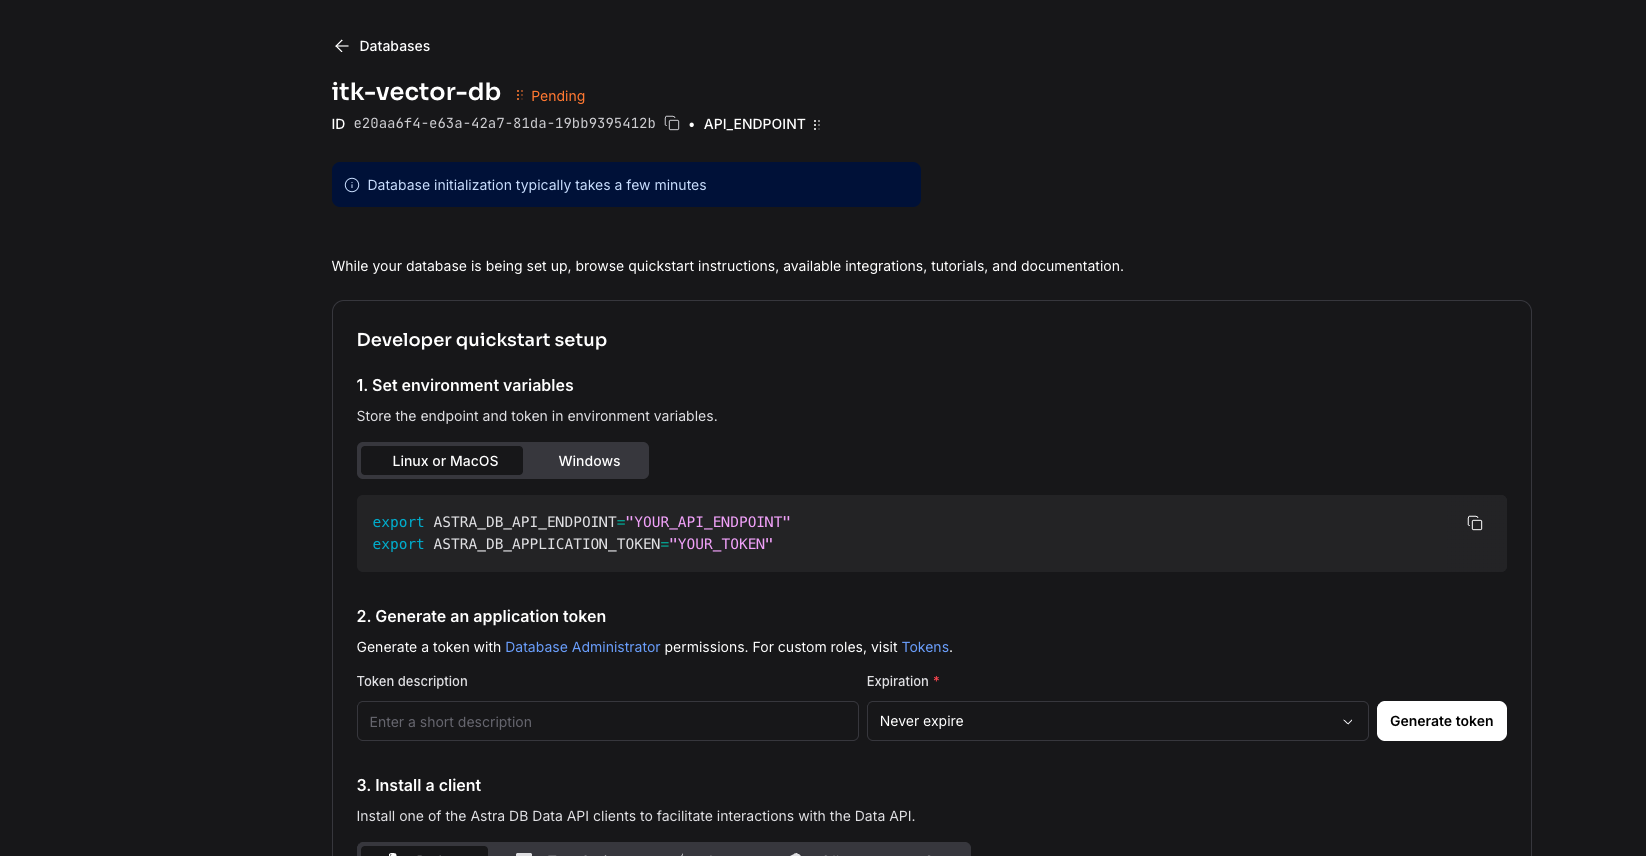

In [4]:
# Libraries import
import os 
from dotenv import load_dotenv
load_dotenv(override=True)
## text loading # directory load #embediings # text splitting
from langchain_community.document_loaders import DirectoryLoader, TextLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_openai import OpenAIEmbeddings

# vector store
from langchain_community.vectorstores import Chroma

#prompt template and LCEL
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import RunnablePassthrough
from langchain_core.output_parsers import StrOutputParser

In [5]:
# stage 1: Load Document 
from docx import document


dir_loader = DirectoryLoader(
    "data",
    glob = "*.txt", # pattern that matches the files
    loader_cls=TextLoader,
    loader_kwargs={
        'encoding':'utf-8'
    },
)

documents = dir_loader.load()
print(f"Total document loaded: {len(documents)}")

Total document loaded: 4


In [6]:
# Stage 2: Document Splitting

text_splitter = RecursiveCharacterTextSplitter(
    chunk_size = 500,
    chunk_overlap = 50,
    length_function = len,
    separators= [" "]
)

chunks = text_splitter.split_documents(documents)
print(f"created {len(chunks)} chunks from {len(documents)} documents")

created 108 chunks from 4 documents


In [7]:
embedings = HuggingFaceEmbeddings(
    model_name = "sentence-transformers/all-MiniLM-L12-v2"
)

embedings

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 8298.53it/s]


HuggingFaceEmbeddings(model_name='sentence-transformers/all-MiniLM-L12-v2', cache_folder=None, model_kwargs={}, encode_kwargs={}, query_encode_kwargs={}, multi_process=False, show_progress=False)

In [8]:
sample_text = "Hello Everyone how are you..."

vector = embedings.embed_query(sample_text)
print(vector[:10])

[-0.020474674180150032, -0.052054379135370255, 0.07710398733615875, -0.002855587750673294, -0.03835587948560715, -0.16038012504577637, 0.046442266553640366, 0.030257975682616234, -0.04812076315283775, -0.03506353870034218]


In [9]:
import os 
from dotenv import load_dotenv
from sqlalchemy import over
load_dotenv(override=True)

os.environ["ASTRA_DB_API_ENDPOINT"] = os.getenv("ASTRA_DB_API_ENDPOINT")
os.environ["ASTRA_DB_APPLICATION_TOKEN"] = os.getenv("ASTRA_DB_APPLICATION_TOKEN")

ASTRA_DB_API_ENDPOINT = os.getenv("ASTRA_DB_API_ENDPOINT")
ASTRA_DB_APPLICATION_TOKEN = os.getenv("ASTRA_DB_APPLICATION_TOKEN")

In [13]:
from langchain_astradb import AstraDBVectorStore

vector_db = AstraDBVectorStore(
    embedding=embedings,  
    api_endpoint=ASTRA_DB_API_ENDPOINT,
    token=ASTRA_DB_APPLICATION_TOKEN,
    collection_name="astra_vector_langchain",
    namespace=None,
)


In [11]:
vector_db

In [14]:
vector_db.add_documents(chunks)

['548496e13e014f8e9a9571c024604206',
 '22a4fe30caad4fccaf1db235be8dd945',
 'aec21c6776494f14aa45caa464695970',
 '2de29af2e0ea42f7af07896c2220eee3',
 '764deb0d26ee4f28a4b25674b0a3f5d4',
 '10f57195e5e14566bb9b7c692c812c63',
 '8d6b7fa6ea8f4d7195727954c727ed7e',
 '8dfc969591874a9f916e5fef41532e31',
 'c1979057268d4837a948b8e6a4fddad2',
 '597b08018db2429b9e36dddac562d267',
 '748deddb7c7e436eb2825b0cacde5984',
 'c2388dcb1f1749629a1bb9c69f6fcf99',
 '5a151e92ee5c40ae96ceb5c18d798841',
 'f8ba8d3535ae4ba781848b3f5ae77907',
 '30b0695f67b7463094a8cf16bd69f74f',
 '94a7d853b46049d7b0a944f125cd4e61',
 '070f21aa465946199d777b73351a2924',
 '7d55e5a3b9114c3683a5e853ee99dce0',
 '790e807c3c4540f5ac0627162282bdf1',
 'dcdf23103b144477bd11b27d637deba6',
 'f74c34008ee34ccf9dfcb86de6dfa70c',
 'e068f0c596fe4ce89fd889dd7745bf42',
 '3b73896c46274f148bc7025f4e5c01d5',
 '04de3a305c0744b686b0e99af306f869',
 '24afc282433d40e2a6ac1c0d6224314b',
 '38ceacefdb6f4709a321ef64f2f19dfa',
 '62dfb27c708c493c9659e147c223854f',
 

In [15]:
from langchain_community.document_loaders import (
    DirectoryLoader,
    PyMuPDFLoader
)

from langchain_text_splitters import RecursiveCharacterTextSplitter
from pathlib import Path
# Check whether your folder contains PDFs
folder_path = Path(
    "/Volumes/ManojData/github/ITK-FREE-GENAI-SERIES-NOTES/DAY-19/New_docs"
)

pdf_files = list(folder_path.rglob("*.pdf"))

print("PDF files found:", len(pdf_files))

for pdf in pdf_files:
    print(pdf.name)

# Load the new documents

loader = DirectoryLoader(
    str(folder_path),
    glob="**/*.[pP][dD][fF]",
    loader_cls=PyMuPDFLoader,
    show_progress=True,
    silent_errors=False
)

new_documents = loader.load()

print("Total pages loaded:", len(new_documents))

for doc in new_documents[:2]:
    print(doc.metadata)
    print(doc.page_content[:200])

PDF files found: 2
fp_monitoring_2000_frep_09_en.pdf
HospitalEpisodeStatistics.pdf


100%|██████████| 2/2 [00:00<00:00,  3.11it/s]

Total pages loaded: 254
{'producer': 'PDF CoDe 1.00.20030707 (c) 2002-2003 European Commission', 'creator': 'Dept of Health', 'creationdate': '2003-10-13T08:24:32+00:00', 'source': '/Volumes/ManojData/github/ITK-FREE-GENAI-SERIES-NOTES/DAY-19/New_docs/fp_monitoring_2000_frep_09_en.pdf', 'file_path': '/Volumes/ManojData/github/ITK-FREE-GENAI-SERIES-NOTES/DAY-19/New_docs/fp_monitoring_2000_frep_09_en.pdf', 'total_pages': 239, 'format': 'PDF 1.4', 'title': 'The Hospital Data Project', 'author': 'Hugh Magee', 'subject': 'Final report', 'keywords': 'European Commission, Public health, health monitoring, Hospital, Data, Project', 'moddate': '2003-10-13T10:55:10+02:00', 'trapped': '', 'modDate': "D:20031013105510+02'00'", 'creationDate': 'D:20031013082432Z', 'page': 0}
Agreement No. SI2.304597 
Hospital Data Project 
 
           
 
 
 
 
 
 
HOSPITAL DATA PROJECT 
 
FINAL REPORT 
 
June 2003
{'producer': 'PDF CoDe 1.00.20030707 (c) 2002-2003 European Commission', 'creator': 'Dept of Health',

In [16]:
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=100
)

new_chunks = text_splitter.split_documents(new_documents)

print("New chunks created:", len(new_chunks))

New chunks created: 657


In [17]:
vector_db.add_documents(new_chunks)

['94844cc519b04ff88474bd34a79feb84',
 '5ba02dffbeff4eff88975e2ed30774c1',
 '6325522ba5234849995b48d231f829bd',
 'be37fb1e6f4643bda6d9ea410a0bc47c',
 '6a30f3cdacdb4296843765560906e033',
 'ff56f78e48a64f238217d4bb0107770d',
 '0e65a5bca1a6485792dba20049b8144b',
 '8038c69a21d34d0d813f772c551571f7',
 'd6b5ab7dc8354d5da82689bbadee7f30',
 '77717f0d975b4546b353cf61325ac335',
 '8b8745dda2c1460ba5224ba3a82cc07b',
 'a025cd8bfd8f42b9a7228cc36c256e3d',
 '25997fffa0d04227b98373422373c0d7',
 'd6392d0b4b5a45468f7c1ddf8edd5cdc',
 '9a15ee50ec63407a950bd91e5e20faa0',
 '49e74c34b7b445b59c7531f79d81cf29',
 '1cf5bb30ea88441eb4b750f01a93fff3',
 'ae17cc11a2e1478faf3fe6c583717508',
 '3c304168d4074170ac355276277e2e31',
 '2334aae24f3b4bc6aaffbe9e66d5c9d3',
 '894235e9361947a49e6435c6a933fbfd',
 '5a792cb699904c0fb2379e4dd9a31089',
 '4b8514672bf546cc8ba50d6cfcfd5787',
 'c416849c1e7e4774b51cac675d891e57',
 'e47ae2530f7b4ae38585f73272671982',
 '4bdd9d9b914043a5b5e41dc03757eb52',
 '559c642a1b124220b60edab3878ee40c',
 

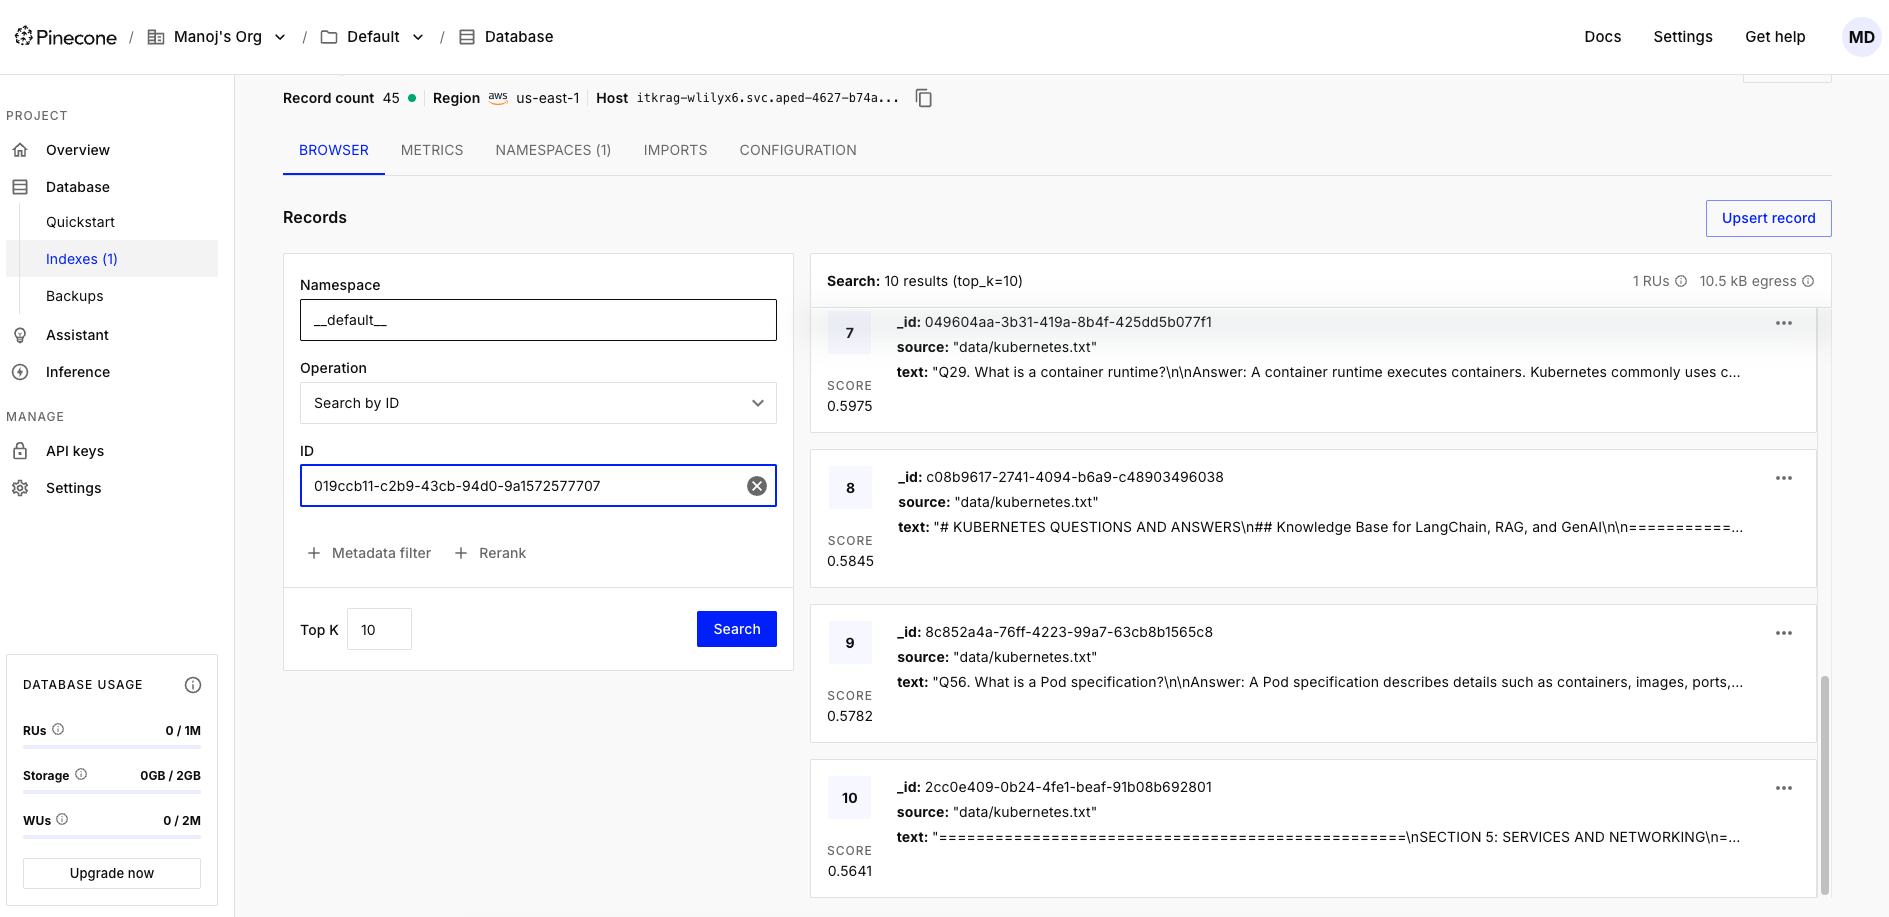

In [23]:
! pip install pinecone


[notice] A new release of pip is available: 26.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [ ]:
from pinecone import Pinecone

pc = Pinecone(api_key="")


In [ ]:
from langchain_openai import OpenAIEmbeddings

embeddings = OpenAIEmbeddings(
    model = "text-embedding-3-small",
    dimensions=1024,
    api_key=""
)

In [29]:
from pinecone import ServerlessSpec
index_name = "itkrag"
if not pc.has_index(index_name):
    pc.create_index(
        name=index_name,
        dimension=1024,
        metric="cosine",
        spec = ServerlessSpec(cloud="aws",region="us-east-1"),
    )

index = pc.Index(index_name)

In [30]:
index

In [35]:
import os
from dotenv import load_dotenv
load_dotenv(override=True)
## text loading # directory load #embediings # text splitting
from langchain_community.document_loaders import DirectoryLoader, TextLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_pinecone import PineconeVectorStore


 
os.environ['PINECONE_API_KEY'] = os.getenv("PINECONE_API_KEY")
os.environ["OPENAI_API_KEY"] = os.getenv("OPENAI_API_KEY")

index_name = "itkrag"
embeddings = OpenAIEmbeddings(
    model="text-embedding-3-small",
    dimensions=512
    )

In [36]:
# path to an example text file
from langchain_community.document_loaders import TextLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter

loader = TextLoader("data/kubernetes.txt")
documents = loader.load()

text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=100
)

docs = text_splitter.split_documents(documents)

print("Total chunks:", len(docs))


Total chunks: 45


In [ ]:
from langchain_pinecone import PineconeVectorStore

vectorstore = PineconeVectorStore.from_documents(
    documents=docs,
    embedding=embeddings,
    index_name="itkrag"
)

print("Documents stored successfully!")

Documents stored successfully!


In [ ]:

query = "What is kubernetes pod..?"

result = vectorstore.similarity_search(
    query,
    k=3
)

for doc in result:
    print(doc.page_content)
    print(doc.metadata)
    print("-"*50)

Q41. What is a Pod?

Answer: A Pod is the smallest deployable unit in Kubernetes. It contains one or more containers that share networking and can share configured storage.

Q42. Can a Pod contain multiple containers?

Answer: Yes. Multiple containers can run in one Pod when they need to work closely together, such as an application container and a logging sidecar.

Q43. What is a sidecar container?

Answer: A sidecar is a supporting container that runs alongside an application container, often providing capabilities such as logging, proxying, or telemetry collection.

Q44. Do containers in the same Pod share an IP address?

Answer: Yes. Containers in the same Pod share the Pod network namespace and IP address, and they can communicate through localhost.

Q45. What happens when a Pod is deleted?

Answer: The Pod is removed. If it is managed by a Deployment or another controller, the controller may create a replacement to maintain the desired state.
{'source': 'data/kubernetes.txt'}
---